In [49]:
import os
import zipfile
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [50]:
df = pd.read_csv("/content/diabetic_data.csv")

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [52]:
print("Missing values:")
print(df.isnull().sum().head(15))

print("\nReadmission counts:")
print(df["readmitted"].value_counts())


Missing values:
encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
weight                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
payer_code                  0
medical_specialty           0
num_lab_procedures          0
num_procedures              0
num_medications             0
dtype: int64

Readmission counts:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [53]:

df.replace("?", np.nan, inplace=True)

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nReadmission counts:")
print(df["readmitted"].value_counts())

Dataset shape: (101766, 50)

Missing values:
weight                 98569
max_glu_serum          96420
A1Cresult              84748
medical_specialty      49949
payer_code             40256
race                    2273
diag_3                  1423
diag_2                   358
diag_1                    21
patient_nbr                0
time_in_hospital           0
admission_source_id        0
num_lab_procedures         0
encounter_id               0
admission_type_id          0
dtype: int64

Readmission counts:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [54]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Keep valid readmission labels
df = df[
    df["readmitted"].isin(["<30", ">30", "NO"])
].copy()

# 1 = readmitted within 30 days
# 0 = not readmitted within 30 days
df["target"] = (df["readmitted"] == "<30").astype(int)

print("Cleaning completed!")
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["target"].value_counts())

Cleaning completed!
Dataset shape: (101766, 51)

Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64


In [55]:
features = [
    "age",
    "gender",
    "time_in_hospital",
    "num_lab_procedures",
    "num_medications",
    "number_inpatient"
]

X = df[features].copy()
y = df["target"].copy()

categorical_features = ["age", "gender"]

numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_medications",
    "number_inpatient"
]

print("Features selected!")
print("Input shape:", X.shape)
display(X.head())

# Fill missing categorical values
X["age"] = X["age"].fillna("Unknown")
X["gender"] = X["gender"].fillna("Unknown")

# Convert categorical columns into binary columns
X = pd.get_dummies(
    X,
    columns=["age", "gender"],
    dtype=int
)

# Handle missing numerical values
num_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_medications",
    "number_inpatient"
]

for col in num_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X[col] = X[col].fillna(X[col].median())

print("Preprocessing completed!")
print("Input shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

display(X.head())

Features selected!
Input shape: (101766, 6)


,age,gender,time_in_hospital,num_lab_procedures,num_medications,number_inpatient
0,[0-10),Female,1,41,1,0
1,[10-20),Female,3,59,18,0
2,[20-30),Female,2,11,13,1
3,[30-40),Male,2,44,16,0
4,[40-50),Male,1,51,8,0


Preprocessing completed!
Input shape: (101766, 17)
Missing values: 0


,time_in_hospital,num_lab_procedures,num_medications,number_inpatient,age_[0-10),age_[10-20),age_[20-30),age_[30-40),age_[40-50),age_[50-60),age_[60-70),age_[70-80),age_[80-90),age_[90-100),gender_Female,gender_Male,gender_Unknown/Invalid
0,1,41,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0
1,3,59,18,0,0,1,0,0,0,0,0,0,0,0,1,0,0
2,2,11,13,1,0,0,1,0,0,0,0,0,0,0,1,0,0
3,2,44,16,0,0,0,0,1,0,0,0,0,0,0,0,1,0
4,1,51,8,0,0,0,0,0,1,0,0,0,0,0,0,1,0


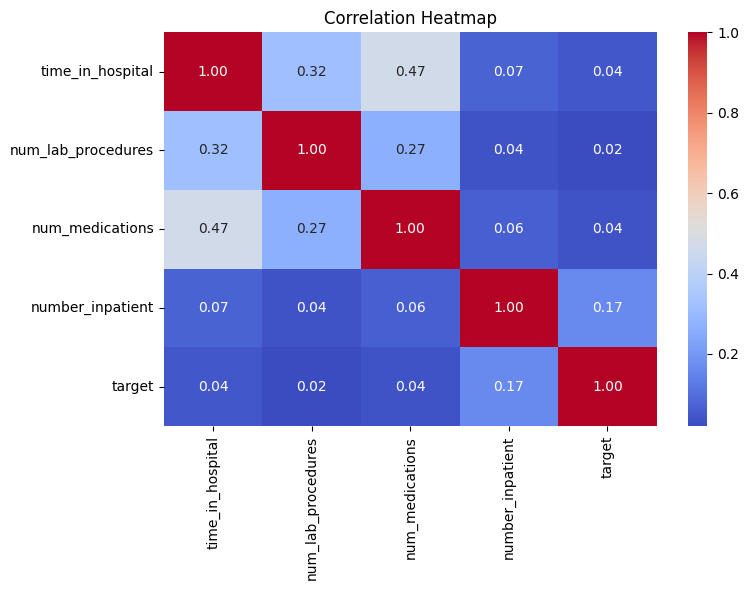

In [56]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_medications",
    "number_inpatient",
    "target"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

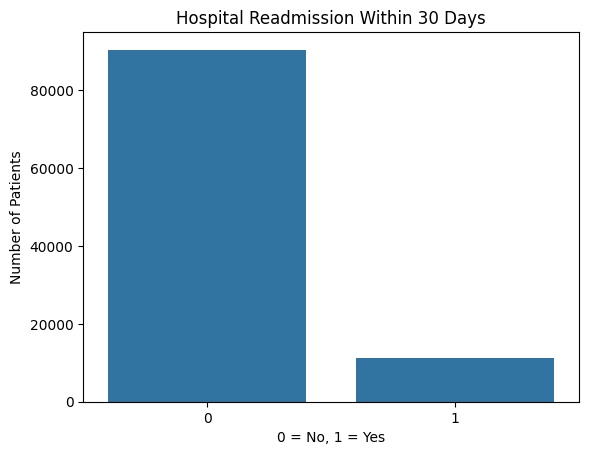

In [57]:
sns.countplot(data=df, x="target")

plt.title("Hospital Readmission Within 30 Days")
plt.xlabel("0 = No, 1 = Yes")
plt.ylabel("Number of Patients")
plt.show()

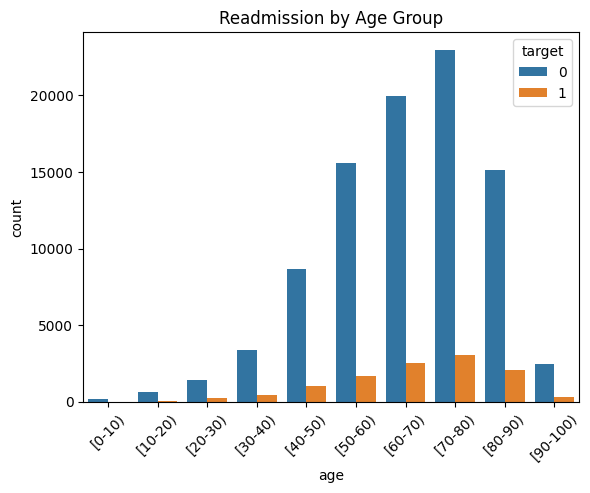

In [58]:
sns.countplot(data=df, x="age", hue="target")

plt.title("Readmission by Age Group")
plt.xticks(rotation=45)
plt.show()

target
0    90409
1    11357
Name: count, dtype: int64


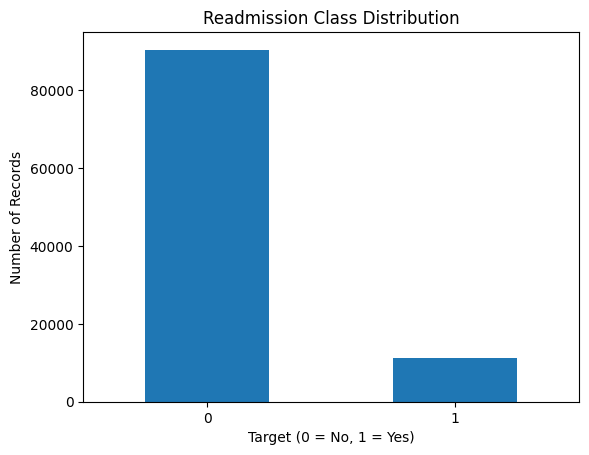

In [59]:
print(df["target"].value_counts())

df["target"].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title("Readmission Class Distribution")
plt.xlabel("Target (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

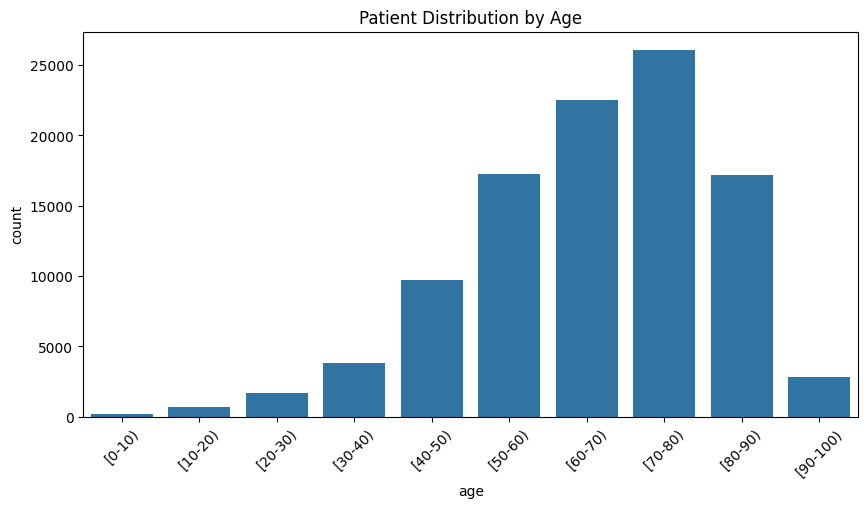

In [60]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="age", order=[
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
])

plt.title("Patient Distribution by Age")
plt.xticks(rotation=45)
plt.show()

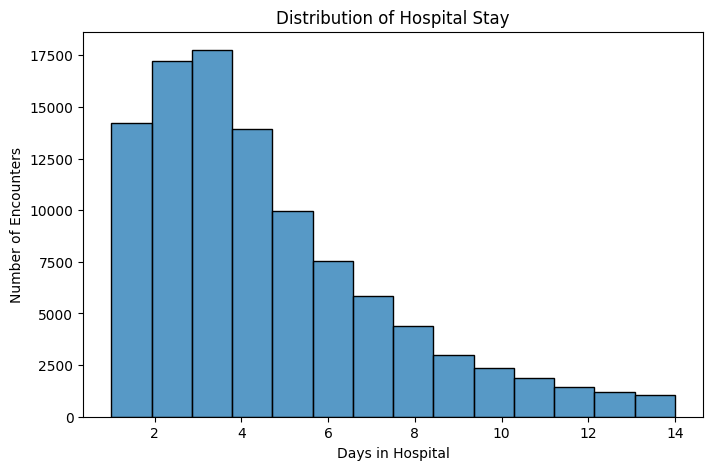

In [61]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14
)

plt.title("Distribution of Hospital Stay")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")
plt.show()

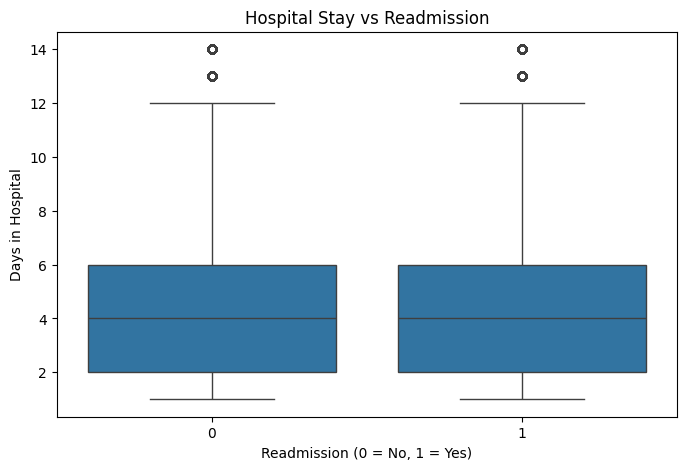

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="time_in_hospital"
)

plt.title("Hospital Stay vs Readmission")
plt.xlabel("Readmission (0 = No, 1 = Yes)")
plt.ylabel("Days in Hospital")
plt.show()

In [63]:
from sklearn.model_selection import GroupShuffleSplit

groups = df.loc[X.index, "patient_nbr"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training patients:", groups_train.nunique())
print("Testing patients:", groups.iloc[test_idx].nunique())

print("Common patients:",
      len(set(groups_train) & set(groups.iloc[test_idx])))

Training records: 81613
Testing records: 20153
Training patients: 57214
Testing patients: 14304
Common patients: 0


In [64]:
model1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model2 = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

model3 = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

models = {
    "Logistic Regression": model1,
    "Decision Tree": model2,
    "Random Forest": model3
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [65]:
from sklearn.model_selection import GroupKFold, cross_val_score

cv = GroupKFold(n_splits=3)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean F1 Score": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Mean F1 Score,Standard Deviation
0,Logistic Regression,0.2487,0.0059
1,Decision Tree,0.2437,0.0038
2,Random Forest,0.2451,0.0018


Selected model: Logistic Regression
Mean CV F1-score: 0.2487


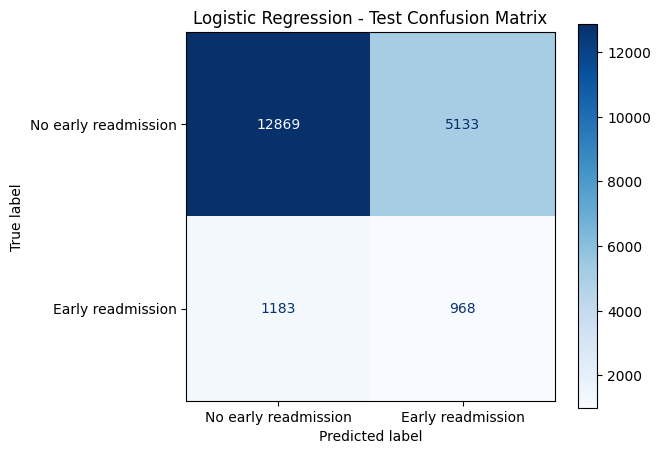

                      precision    recall  f1-score   support

No early readmission       0.92      0.71      0.80     18002
   Early readmission       0.16      0.45      0.23      2151

            accuracy                           0.69     20153
           macro avg       0.54      0.58      0.52     20153
        weighted avg       0.83      0.69      0.74     20153



In [70]:
# Select the best model using cross-validation F1-score
best_index = cv_df["Mean F1 Score"].idxmax()
best_name = cv_df.loc[best_index, "Model"]
best_model = models[best_name]

print("Selected model:", best_name)
print("Mean CV F1-score:",
      round(cv_df.loc[best_index, "Mean F1 Score"], 4))

# Evaluate on the held-out test set
best_predictions = best_model.predict(X_test)

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["No early readmission", "Early readmission"],
    cmap="Blues"
)

plt.title(f"{best_name} - Test Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    best_predictions,
    target_names=["No early readmission", "Early readmission"],
    zero_division=0
))

In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

best_probabilities = best_model.predict_proba(X_test)[:, 1]

final_results = pd.DataFrame([{
    "Selected Model": best_name,
    "Accuracy": accuracy_score(y_test, best_predictions),
    "Precision": precision_score(
        y_test, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, best_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, best_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, best_probabilities
    )
}])

display(final_results.round(4))

,Selected Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6866,0.1587,0.45,0.2346,0.6233


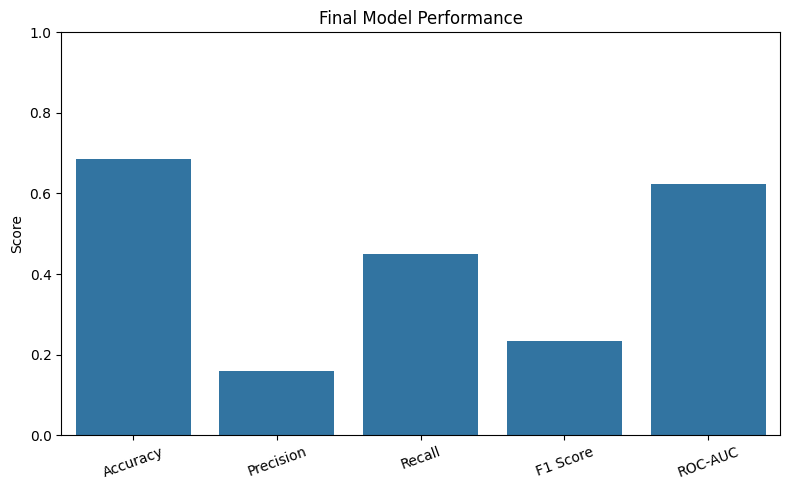

In [69]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

values = final_results[metrics].iloc[0]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=metrics,
    y=values.values
)

plt.title("Final Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()